# Desenvolvimento do modelo de  Regressão Logística - Binário
---

***À Fazeres:***

1. Olhar [esse repo](https://github.com/ICEI-PUC-Minas-PMV-SI/pmv-si-2026-1-pe7-t3-g1-pesquisaexperimentacao-2026-1) do colega Luiz Henrique do grupo 2 sobre `t-SNE`
2. Olhar sobre  a `Curva PR (Precison - Recall)`

A `Regressão Logística` é um algoritmo fundamental de aprendizado supervisionado utilizado para problemas de classificação, apesar de carregar "regressão" no nome.

Diferente da Regressão Linear, que prevê números contínuos, a Regressão Logística prevê a probabilidade de uma amostra pertencer a uma classe específica (geralmente binária, como `Sim` e `Não` ou `0` e `1`).

Utiliza de:

- O algoritmo utiliza a `Função Logística` (ou `Sigmóide`) para "achatar" qualquer valor numérico em um intervalo entre 0 e 1.
- Define-se um limiar (geralmente 0,5). Se a probabilidade calculada for maior que 0,5, o modelo classifica como classe A; se for menor, como classe B.

Uso em `Machine Learning`:

- `Classificação Binária`: É o uso mais comum. Exemplos incluem detecção de spam, diagnóstico médico, aprovação de crédito e no caso deste projeto, determinar a probabilidade de ser um ataque cibernético.

- `Base para Modelos Complexos`: É frequentemente usada como um baseline (modelo de referência inicial) devido à sua simplicidade e rapidez.

- `Interpretabilidade`: Em Machine Learing, é muito valorizada porque permite entender o peso de cada variável na decisão final (quão importante cada característica é para a probabilidade).


Principais fórmulas estatísticas:

1. `Equação Linear (Logit)`:

   Antes de chegar à probabilidade, o modelo calcula um valor intermediário ($z$), que é uma combinação linear dos atributos (features) do seu conjunto de dados:

   <div style="text-align: center;">
      <img src="../../imagens/logit.png" width="480">
   </div>


2. `Função Sigmóide (Função Logística)`:
  
   Para converter esse valor `z` (que pode ir de `-infinito` a `+infinto`) em uma probabilidade `P` entre 0 e 1, utiliza-se a `função sigmóide`:

    <div style="text-align: center;">
      <img src="../../imagens/funcao_sigmoide.png" width="480">
    </div>

3. `Função de Custo (Log Loss / Entropia Cruzada)`:

Não se usa o `Erro Quadrático Médio` (como na regressão linear) porque a `sigmóide` tornaria a função não-convexa. Usa-ses `Log Loss`:

<div style="text-align: center;">
  <img src="../../imagens/log_loss.png" width="480">
</div>

4. `Razão de Chances (Odds Ratio)`:

    A `Regressão Logística` também pode ser expressa em termos de `odds (chances)`, que é a razão entre a probabilidade de sucesso e a de fracasso:

<div style="text-align: center;">
  <img src="../../imagens/odds_ratio.png" width="480">
</div>

## A) Importando as Bibliotecas e Pacotes a serem usados
---

### 1. Pacotes baixados:
---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report, RocCurveDisplay, precision_recall_curve
from sklearn.preprocessing import PolynomialFeatures, RobustScaler
from imblearn.over_sampling import SMOTE

### 2. Pacote Predexan:
---

In [2]:
import sys
import os

caminho_predexan = os.path.abspath(os.path.join(os.getcwd(), '../..'))

if caminho_predexan not in sys.path:
    sys.path.append(caminho_predexan)

print(f"Buscando em: {caminho_predexan}")
print(f"Pastas encontradas: {os.listdir(caminho_predexan)}")

import predexan.graficos as pg
import predexan.metricas as pm
import predexan.preproc as pp

Buscando em: C:\Users\rmaca\PUC_eixo7\projeto\pmv-si-2026-1-pe7-t3-g1-pesquisaexperimentacao-2026-1\src
Pastas encontradas: ['.ipynb_checkpoints', 'analise_exploratoria_pre_processamento', 'dataset', 'imagens', 'modelos', 'predexan', 'README.md']


## B) Determinando os Dataframes à partir das bases de dados pré-processados
---

### 1. Determinando df_treino
---

In [3]:
df_treino = pd.read_parquet('../../dataset/pre_processado/treino_pre_processado.parquet')
df_treino.info()

<class 'pandas.DataFrame'>
Index: 96822 entries, 0 to 175337
Data columns (total 36 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   duracao_conexao_seg                 96822 non-null  float64
 1   protocolo_rede                      96822 non-null  float64
 2   servico_conexao                     96822 non-null  float64
 3   estado_conexao                      96822 non-null  float64
 4   num_pacotes_origem                  96822 non-null  float64
 5   num_pacotes_destino                 96822 non-null  float64
 6   total_bytes_origem                  96822 non-null  float64
 7   total_bytes_destino                 96822 non-null  float64
 8   taxa_pacote                         96822 non-null  float64
 9   carga_origem                        96822 non-null  float64
 10  carga_destino                       96822 non-null  float64
 11  pacotes_perdidos_origem             96822 non-null  floa

### 2. Determinando df_teste
---

In [4]:
df_teste = pd.read_parquet('../../dataset/pre_processado/teste_pre_processado.parquet')
df_teste.info()

<class 'pandas.DataFrame'>
Index: 49971 entries, 0 to 82328
Data columns (total 36 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   duracao_conexao_seg                 49971 non-null  float64
 1   protocolo_rede                      49971 non-null  float64
 2   servico_conexao                     49971 non-null  float64
 3   estado_conexao                      49971 non-null  float64
 4   num_pacotes_origem                  49971 non-null  float64
 5   num_pacotes_destino                 49971 non-null  float64
 6   total_bytes_origem                  49971 non-null  float64
 7   total_bytes_destino                 49971 non-null  float64
 8   taxa_pacote                         49971 non-null  float64
 9   carga_origem                        49971 non-null  float64
 10  carga_destino                       49971 non-null  float64
 11  pacotes_perdidos_origem             49971 non-null  float

## C) Separando os valores em teste e treino
---

Nessa seção, serão separadas as `features` do `target`, tanto para a base de testes quanto de treino.

Há duas possibilidades claras de `target`, presentes nos datasets, dado o cenário de `Classificação` e `Regressão Logística`: `label`e `categoria_ataque.

A primeira retornaria um diagnóstico apontado se há uma probabilidade alta ou baixa de haver um ataque, de maneira geral. Já a segunda, retornaria a probabilidade de haver um ataque específico dentro de suas dez classes.

A escolha do target se embasa tanto na especialização da resposta, quanto no desempenho e custo computacional do modelo. Dessa forma, ao escolher `label`, a resposta é mais simples, mas continua sendo de grande valor, e o custo computacional é muito inferior. Já a escolha de `categoria_ataque`, traz uma resposta mais especializada e de maior qualidade para o usuário, contudo o custo computacional se mostrou alto.

A escolha de target **provisória** é `label` por conta da razão utilidade/custo computacional, mas ainda será ***conversado com o professor*** a possibilidade de se voltar a usar `categoria_ataque`, mesmo que este não tenha sido processado de forma eficiente pelas máquinas a disposição, em primeiro momento. 

### 1. Atributos do df_treino
---

In [5]:
# Features
X_treino = df_treino.drop(columns=['label', 'categoria_ataque'])

# Target
y_treino = df_treino['label']

### 2. Atributos do df_teste
---

In [6]:
# Features
X_teste = df_teste.drop(columns=['label', 'categoria_ataque'])

# Target
y_teste = df_teste['label']

## D) Desenvolvimento do Modelo
---

### 1. Aplicação da classe SMOTE para balanceamento de classes nas variáveis de treino
---

- Target **label**:

O uso da classe `SMOTE`se mostra **injustificado** para o target `label` uma vez que ele já está naturalmente balanceado na base de treino.

In [7]:
df_treino['label'].value_counts()

label
0.0    48894
1.0    47928
Name: count, dtype: int64

### 2. Aplicação de PolynomialFeatures
---

***Tirar Dúvida com o professor sobre funcionalidade para o projeto e desempenho.***

A aplicação de `PolynomialFeatures` busca gerar interações entre as variáveis, permitindo que o modelo de `Regressão Logística` capture relações não-lineares nos dados. Isso aumenta a complexidade do espaço de atributos, possibilitando o mapeamento de padrões mais sofisticados que impactam o alvo, mas que não são perceptíveis de forma linear isolada.

#### 2.1. Criação da instância da função PolynomialFeatures
---

In [8]:
poly = PolynomialFeatures(degree=2)

#### 2.2. Aprendizagem e transformação com as features do Dataset de Treino
---

In [9]:
X_treino_poly = poly.fit_transform(X_treino)
X_treino_poly

array([[ 1.00000000e+00, -5.42402662e-03,  1.13000000e+02, ...,
         0.00000000e+00,  0.00000000e+00,  3.60000000e+01],
       [ 1.00000000e+00,  3.44877546e-03,  1.13000000e+02, ...,
         0.00000000e+00,  0.00000000e+00,  3.60000000e+01],
       [ 1.00000000e+00,  1.97902947e-02,  1.13000000e+02, ...,
         0.00000000e+00,  0.00000000e+00,  3.60000000e+01],
       ...,
       [ 1.00000000e+00,  9.26857591e-03,  1.13000000e+02, ...,
         0.00000000e+00,  0.00000000e+00,  9.00000000e+00],
       [ 1.00000000e+00,  1.86820166e-02,  1.13000000e+02, ...,
         0.00000000e+00,  0.00000000e+00,  9.00000000e+00],
       [ 1.00000000e+00,  1.02851111e-03,  1.13000000e+02, ...,
         0.00000000e+00,  0.00000000e+00,  6.40000000e+01]],
      shape=(96822, 666))

#### 2.3. Normalização das Features de Treino
---

Foi visto no array de `X_treino_poly` que seus valores foram desnormalizados com  a aplicação de PolynomialFeatures, portanto, estes devem ser normalizados. Uma boa oção para esse caso é o `RobustScaler` pois as bases de dados são naturalmente não normais e com grandes quantidade de outliers, além de ele já ter sido usado nos notebooks de pré-processamento de dados destas bases.

In [10]:
type(X_treino_poly)

numpy.ndarray

É necessário transformar os arrays em df para ter maior controle das features e seus dados.

##### 2.4.1. Instanciamento da classe RobustScaler()
---

In [11]:
escalonador = RobustScaler()

##### 2.4.2. Normalização de X_treino_poly
---

In [12]:
novas_colunas = poly.get_feature_names_out(X_treino.columns)

# Conversão para df
X_treino_poly = pd.DataFrame(X_treino_poly, columns=novas_colunas)

# Lista que contém os atributos categóricos e/ou com poucos valores únicos
atr_nao_categoricos_treino = X_treino_poly.drop(columns=['protocolo_rede','tamanho_janela_tcp_origem', 'servico_conexao','estado_conexao', 'categoria_ataque'])

# Loop que normaliza e compara as amplitudes antes e depois
for feature in atr_nao_categoricos_treino:
    # _, valor_min, valor_max, _, _, faixa = pm.gerar_dispersao(X_treino_poly, feature)
    # print(f'\n\nAtributo {feature.upper()}:\n')
    # print(f'O atributo {feature} possui amplitude entre {valor_min} e {valor_max} e magnitude {faixa} antes da Normalização com RobustScaler.\n')
    
    normalizacao = pp.normalizar_feature_rs(X_treino_poly, feature, escalonador, div_max=True)
    X_treino_poly[feature] = normalizacao
    
    # _, valor_min, valor_max, _, _, faixa = pm.gerar_dispersao(X_treino_poly, feature)
    # print(f'O atributo {feature} foi normalizado. Sua amplitude atual está entre {valor_min} e {valor_max} e sua magnitude, em {faixa}.\n')

### 3. Treino do modelo
---

O treino do modelo será feito com o instanciamento da classe `LogisticRegression` do pacote `Scikit-Learn`.

#### 3.1. Instanciamento da classe LogisticRegression
---

In [13]:
modelo = LogisticRegression(random_state=42, max_iter=6000, solver='saga', penalty='elasticnet', l1_ratio=0.5, C=5.0)

#### 3.2. Explicação dos parâmetros usados no modelo de Regressão Logística
---

##### 3.2.1. Parâmetros de Controle e Performance
---

- `random_state=42`: Garante a `reprodutibilidade`. Ele fixa o algoritmo de aleatoriedade para que, toda vez que o código for rodado, o modelo chegue exatamente ao mesmo resultado.

- `max_iter=3000`: É o número máximo de iterações que o algoritmo tem para encontrar os melhores pesos. Valores altos como 3000 ajudam o modelo a convergir (chegar na resposta final) em datasets complexos.

- `solver='saga'`: É o "motor" matemático que otimiza o modelo. O saga é uma boa escolha para datasets grandes e é o único que suporta todas as penalidades.

##### 3.2.1. Parâmetros de Regularização (evitam Overfitting)
---

- `penalty='elasticnet'`: É um tipo de regularização "híbrida". Ela combina o `L1` (que pode zerar coeficientes inúteis, selecionando variáveis) e o `L2` (que apenas diminui os pesos para evitar extremos).

- `l1_ratio=0.5`: Como `elasticnet` foi a penalidade escolhida, este parâmetro define o uso de `L1` e `L2`. 0.5 significa que você está usando 50% de `L1` e 50% de `L2`.

- `C=5.0`: Controla a força da regularização. Funciona ao inverso: valores menores de `C` aplicam uma regularização mais forte. Um C=5.0 é considerado alto. Isto significa que está se confiando muito nos dados de treino e aplicando uma penalidade mais leve.

#### 3.3. Treino do modelo de Regressão Logística
---

In [14]:
pm.imprimir_desempenho(modelo.fit,X_treino_poly, y_treino)

- RELATÓRIO DE DESEMPENHO:

    1. Tempo:

      Tempo de processamento: 5838.7541 segundos ou 97.31 minutos.

    2. Uso de Memória RAM:

      Atual: 570520 Bytes ou 0.54 MegaBytes | Pico: 1032250778 Bytes ou 984.43 MegaBytes.




C:\Users\rmaca\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


LogisticRegression(C=5.0, l1_ratio=0.5, max_iter=6000, penalty='elasticnet',
                   random_state=42, solver='saga')

### 4. Predições com base de testes
---

Serão determinadas duas variáveis de predição: 

1. `y_predicao_proba` - predição probabilística que retorna a probailidade de haver um ataque. Será usada pelo modelo, caso seja escolhido para ser usado na aplicação.
2. `y_predicao_binaria` - predição binária que retorna verdadediro ou falso. Será usada como referência nas análises de métricas de desempenho em `Pontuação`, `Matriz de Confusão` e `Relatório de Classificação`.

#### 4.1. Predição Probabilística
---

In [1]:
y_predicao_binaria = pm.imprimir_desempenho(modelo.predict_proba,X_teste)

NameError: name 'pm' is not defined

#### 4.2. Predição Binária
---

In [2]:
y_predicao_binaria = pm.imprimir_desempenho(modelo.predict,X_teste)

NameError: name 'pm' is not defined

### 5. Desempenho do modelo
---

O modelo possui métricas de desempenho baseadas nos resultados dos testes, sendo essas: 

- `Pontuação` que traz a `Acurácia Geral`.
- `Matriz de Confusão` que traz os acertos e erros de inferência.
-  `Relatório de Classificação` que traz cálculos como `Precision`, `Recall` e `F1-Score`.
-  `Curva ROC AUC` que traz uma visualização gráfica.

#### 5.1. Matriz de Confusão
---

A `Matriz de Confusão` permite a visualização do desempenho do modelo, uma vez que mostra o total de predições `Verdadeiras Positivas (TP)`, `Verdadeiras Negativa (TN)`, `Falsas Positivas (FP)` e `Falsas Negativas (FN)`. No contexto do projeto, que visa a probailidade de `detecção de ameaças`, os alvos são sempre atingir ao máximo`TN` e `TP`, mas `FN` é o erro crítico, pois pode levar ao usuário da aplicação a ignorar a hipótese do ataque em sua máquina, podendo propiciar uma piora no caso, já que este pode deixar de buscar ajuda e manutenções e `FP` é o alarme falso. 

##### 5.1.1. Criação da Matriz de Confusão 
---

In [36]:
matriz_confusao = confusion_matrix(y_teste, y_predicao_binaria)

##### 5.1.2. Visualização da Matriz de Confusão 
---

<Axes: >

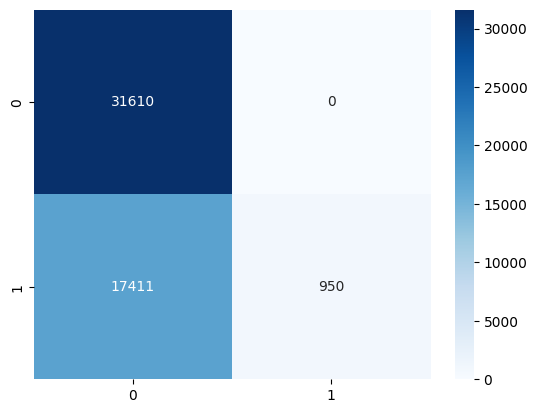

In [37]:
matriz_confusao = confusion_matrix(y_teste, y_predicao_binaria)
sns.heatmap(matriz_confusao, annot=True, fmt='d', cmap='Blues')

##### 5.1.3. Análises da Matriz de Confusão
---

In [38]:
(tn, fp), (fn, tp) = matriz_confusao
total = (tn+fn+tp+fp)

In [39]:
print(f'O total de predições de teste foi {total}.')

print(f'\n - Verdadeiro Negativo (TN): Predição correta sobre o classificação negativa. Há {tn} casos que o modelo apontou como resultado negativo, corretamente. Representa {pm.calcular_percentual(tn, total):.2f}% do total de predições de teste.')
print(f'\n - Falso Negativo (FN): Predição incorreta sobre o classificação negativa. Há {fn} casos em que o modelo apontou como resultado negativo, erroneamente. Maior risco pois, possivelmente, o usuário não buscará ajuda para o caso de ataque cibernético, por acreditar não ser necessário. Representa {pm.calcular_percentual(fn, total):.2f}% do total de predições de teste.')
print(f'\n - Verdadeiro Positivo (TP): Predição correta sobre o classificação positiva. Há {tp} casos em que o modelo apontou como resultado positivo, corretamente. Representa {pm.calcular_percentual(tp, total):.2f}% do total de predições de teste.')
print(f'\n - Falso Positivo (FP): Predição incorreta sobre o classificação positiva. Há {fp} casos em que o modelo apontou como resultado positivo, erroneamente. Este é o alarme falso. Representa {pm.calcular_percentual(fp, total):.2f}% do total de predições de teste.')
print(f'\n\nResultados:')

print(f'\n - A quantidade de vezes que o modelo acertou é expressa por TN + TP e é igual a {(tn + tp)}, de um total de {total}. Isto corresponde a, aproximadamente, {pm.calcular_percentual((tn+tp), total):.2f}% do total de predições.')
print(f'\n - A quantidade de vezes que o modelo errou é expressa por FN + FP e é igual a {(fn + fp)}, de um total de {total}. Isto corresponde a, aproximadamente, {pm.calcular_percentual((fn+fp), total):.2f}% do total de predições.\n\n')

O total de predições de teste foi 49971.

 - Verdadeiro Negativo (TN): Predição correta sobre o classificação negativa. Há 31610 casos que o modelo apontou como resultado negativo, corretamente. Representa 63.26% do total de predições de teste.

 - Falso Negativo (FN): Predição incorreta sobre o classificação negativa. Há 17411 casos em que o modelo apontou como resultado negativo, erroneamente. Maior risco pois, possivelmente, o usuário não buscará ajuda para o caso de ataque cibernético, por acreditar não ser necessário. Representa 34.84% do total de predições de teste.

 - Verdadeiro Positivo (TP): Predição correta sobre o classificação positiva. Há 950 casos em que o modelo apontou como resultado positivo, corretamente. Representa 1.90% do total de predições de teste.

 - Falso Positivo (FP): Predição incorreta sobre o classificação positiva. Há 0 casos em que o modelo apontou como resultado positivo, erroneamente. Este é o alarme falso. Representa 0.00% do total de predições de te

#### 5.2. Pontuação do Modelo (Acurácia Geral)
---

A `Acurácia Geral` tem como foco apontar quantas predições foram assertivas no total. Pode ser uma métrica errônea em conjuntos de dados desbalanceados. Em situações como essa, o modelo pode investir nos casos mais óbvios e deixando a resposta "pré-programada", como um chute, deixando uma acurácia alta e uma eficiência baixa. Dessa forma, esta métrica deve se analisada sempre em conjunto com as demais para garantir o sucesso do modelo.

<div style="text-align: center;">
  <img src="../../imagens/formula_accuracy.png" width="400">
</div>

##### 5.2.1. Criação e visualização da Pontuação do Modelo
---

In [41]:
acuracia = modelo.score(X_teste_poly, y_teste)

C:\Users\rmaca\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [42]:
print(f'A Acurácia Geral do modelo é de, aproximadamente, {pm.calcular_percentual(acuracia, 1):.2f}%.')

A Acurácia Geral do modelo é de, aproximadamente, 65.16%.


#### 5.3. Relatório de Classificação
---

O `Relatório de Classificação` apresenta métricas de desempenho que mostram o quanto o modelo acerta, utilizando as noções da `Matriz de Confusão` como TN, FN, TP, FP.

1. Precision (Precisão): tem como foco evitar Alarmes Falsos (Falsos Positivos). Uma precisão alta significa que o modelo é cauteloso ao rotular algo como positivo

<div style="text-align: center;">
  <img src="../../imagens/formula_precisao.png" width="400">
</div>

2. Recall (Revocação): tem como foco evitar omissões do modelo. Um recall alto significa que o modelo consegue percorrer por quase todos os casos importantes, mesmo que arrisque alguns alarmes falsos, mas evite falsos negativos.

<div style="text-align: center;">
  <img src="../../imagens/formula_recall.png" width="400">
</div>

3. F1-Score (Valor F1): É a média harmônica entre Precision e Recall. Boa métrica para perceber quando se tem classes desbalanceadas e precisa de um único número que resuma a eficiência da predição.

<div style="text-align: center;">
  <img src="../../imagens/formula_f1score.png" width="400">
</div>

###### 5.3.1. Criação e visualização do Relatório de Classificação
---

In [43]:
relatorio_classificacao = classification_report(y_teste, y_predicao_binaria)

In [44]:
print(relatorio_classificacao)

              precision    recall  f1-score   support

         0.0       0.64      1.00      0.78     31610
         1.0       1.00      0.05      0.10     18361

    accuracy                           0.65     49971
   macro avg       0.82      0.53      0.44     49971
weighted avg       0.78      0.65      0.53     49971



###### 5.3.2. Extração dos dados do Relatório de Classificação
---

Para a extração dos dados do Relatório de Classificação, deve-se transformar suas saídas em dicionários, à partir do parâmetro `output_dict`.  

In [45]:
dict_relatorio_classificacao = classification_report(y_teste, y_predicao_binaria, output_dict=True)

In [46]:
print(dict_relatorio_classificacao.keys())

dict_keys(['0.0', '1.0', 'accuracy', 'macro avg', 'weighted avg'])


In [47]:
precision_0 = dict_relatorio_classificacao['0.0']['precision']
precision_1 = dict_relatorio_classificacao['1.0']['precision']

recall_0 = dict_relatorio_classificacao['0.0']['recall']
recall_1 = dict_relatorio_classificacao['1.0']['recall']

f1_score_0 = dict_relatorio_classificacao['0.0']['f1-score']
f1_score_1 = dict_relatorio_classificacao['1.0']['f1-score']

support_0 = dict_relatorio_classificacao['0.0']['support']
support_1 = dict_relatorio_classificacao['1.0']['support']
support = support_0 + support_1

macro_avg_precision = dict_relatorio_classificacao['macro avg']['precision']
weighted_avg_precision = dict_relatorio_classificacao['weighted avg']['precision']

macro_avg_recall = dict_relatorio_classificacao['macro avg']['recall']
weighted_avg_recall = dict_relatorio_classificacao['weighted avg']['recall']

macro_avg_f1 = dict_relatorio_classificacao['macro avg']['f1-score']
weighted_avg_f1 = dict_relatorio_classificacao['weighted avg']['f1-score']

###### 5.3.3. Análise do Relatório de Classificação a partir de seus dados
---

In [48]:
print('Análises do Relatório de Classificação:')
print('\nCasos onde não foram detectadas ameaças:')
print(f'\n - O total de casos é de {support_0}:')
print(f'\n - Precision é igual a {precision_0} ou {pm.calcular_percentual(precision_0, support_0):.2f}%. Isto corresponde a {(support_0 * precision_0)} predições de testes.')
print(f'\n - Recall é igual a {recall_0} ou {pm.calcular_percentual(recall_0, support_0):.2f}%. Isto corresponde a {(support_0 * recall_0)} predições de testes.')
print(f'\n - F1-Score é igual a {f1_score_0} ou {pm.calcular_percentual(f1_score_0, support_0):.2f}%. Isto corresponde a {(support_0 * f1_score_0)} predições de testes.')

print('\n\nCasos onde foram detectadas ameaças:')
print(f'\n - O total de casos é de {support_1}:')
print(f'\n - Precision é igual a {precision_1} ou {pm.calcular_percentual(precision_1, support_1):.2f}%. Isto corresponde a {(support_1 * precision_1)} predições de testes.')
print(f'\n - Recall é igual a {recall_1} ou {pm.calcular_percentual(recall_1, support_1):.2f}%. Isto corresponde a {(support_1 * recall_1)} predições de testes.')
print(f'\n - F1-Score é igual a {f1_score_1} ou {pm.calcular_percentual(f1_score_1, support_1):.2f}%. Isto corresponde a {(support_1 * f1_score_1)} predições de testes.')

print('\n\nAs médias foram:')
print('\n Média Aritmética (Macro AVG):')
print(f'\n - O total de casos é {support}')
print(f'\n - Precision: {macro_avg_precision} ou {pm.calcular_percentual(macro_avg_precision, 1):.2f}%. Isto corresponde a {(support * macro_avg_precision)}.')
print(f'\n - Recall: {macro_avg_recall} ou {pm.calcular_percentual(macro_avg_recall, 1):.2f}%. Isto corresponde a {(support * macro_avg_recall)}.')
print(f'\n - F1-Score: {macro_avg_f1} ou {pm.calcular_percentual(macro_avg_f1, 1):.2f}%. Isto corresponde a {(support * macro_avg_f1)}.')

print('\n\n Média Ponderada (Weighted AVG):')
print(f'\n - O total de casos é {support}')
print(f'\n - Precision: {weighted_avg_precision} ou {pm.calcular_percentual(weighted_avg_precision, 1):.2f}%. Isto corresponde a {(support * weighted_avg_precision)}.')
print(f'\n - Recall: {weighted_avg_recall} ou {pm.calcular_percentual(weighted_avg_recall, 1):.2f}%. Isto corresponde a {(support * weighted_avg_recall)}.')
print(f'\n - F1-Score: {weighted_avg_f1} ou {pm.calcular_percentual(weighted_avg_f1, 1):.2f}%. Isto corresponde a {(support * weighted_avg_f1)}.')

Análises do Relatório de Classificação:

Casos onde não foram detectadas ameaças:

 - O total de casos é de 31610.0:

 - Precision é igual a 0.6448256869504906 ou 0.00%. Isto corresponde a 20382.939964505007 predições de testes.

 - Recall é igual a 1.0 ou 0.00%. Isto corresponde a 31610.0 predições de testes.

 - F1-Score é igual a 0.7840656819337476 ou 0.00%. Isto corresponde a 24784.316205925763 predições de testes.


Casos onde foram detectadas ameaças:

 - O total de casos é de 18361.0:

 - Precision é igual a 1.0 ou 0.01%. Isto corresponde a 18361.0 predições de testes.

 - Recall é igual a 0.051740101301672024 ou 0.00%. Isto corresponde a 950.0 predições de testes.

 - F1-Score é igual a 0.0983895189270364 ou 0.00%. Isto corresponde a 1806.5299570193154 predições de testes.


As médias foram:

 Média Aritmética (Macro AVG):

 - O total de casos é 49971.0

 - Precision: 0.8224128434752453 ou 82.24%. Isto corresponde a 41096.79220130148.

 - Recall: 0.525870050650836 ou 52.59%. Is

#### 5.4. Curva ROC AUC
---

A curva `ROC (Receiver Operating Characteristic)` e a métrica `AUC (Area Under the Curve)` são ferramentas muito importantes para a medição de desempenho de `Modelos de Classificação`. Ela mede a capacidade do modelo em distinguir as classes: quanto maior o AUC, melhor o modelo é em prever 0 como 0 e 1 como 1, mas ainda assim, é melhor para medir o desempenho das probabilidades com o método `predict_proba` do que com o `predict`.

1. Curva ROC: É um gráfico que ilustra o equilíbrio entre a Taxa de Verdadeiros Positivos (Sensibilidade) e a Taxa de Falsos Positivos (1 - Especificidade) para todos os limiares (thresholds) possíveis de classificação.

2. AUC (Área sob a Curva): É um valor numérico que varia de 0 a 1 e resume a performance do modelo:

   - 1.0: Classificador perfeito.

   - 0.5: Classificador aleatório (equivalente ao acaso).

   -  Acima de 0.7: Geralmente indica um bom poder preditivo.
  
3. Os eixos são os seguintes:

    - Eixo Y (Taxa de Verdadeiro Positivo / Sensibilidade): Representa o Recall. Quanto mais alto, melhor para o modelo, já que este será mais abrangente ao processar os dados, conseguindo capturar um maior número de ameaças.

    - Eixo X (Taxa de Falso Positivo): É o custo do erro. Ele mostra, em relação a todos os casos normais, quantos o modelo marcou erradamente como ameaça. Quanto mais baixo (à esquerda), melhor.
  
4. A "Linha de Sorte" (Pontilhada):

    - A linha diagonal representa um modelo que decide com aleatoriedade.

    - Se curva estiver próximo a essa linha diagonal, ele será pouco útil.
  
    - Se estiver acima, mais distante, terá uma utilidade maior, por não depender tanto de aleatoriedade.
  
5. O Ponto Ideal:

    O objetivo do modelo é chegar o mais próximo possível do canto superior esquerdo (coordenada 0.0 no X e 1.0 no Y). 

##### 5.4.1. Plot do gráfico da Curva ROC AUC
---

C:\Users\rmaca\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


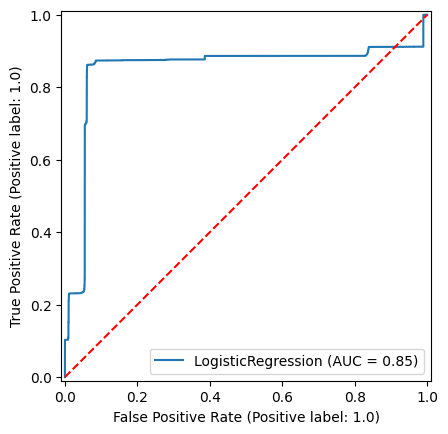

In [50]:
curva = RocCurveDisplay.from_estimator(modelo, X_teste_poly, y_teste)
plt.plot([0, 1], [0, 1], color='red', linestyle='--')
plt.show()

##### 5.4.2. Extração do valor de AUC
---

In [51]:
auc_valor = curva.roc_auc
print(f'O valor de AUC do modelo é {auc_valor}.')

O valor de AUC do modelo é 0.8492572742443842.


##### 5.4.3. Análise do gráfico
---

O gráfico da `Curva ROC AUC` apresenta a curva muito acima da linha tracejada, estando a maior parte junto ao eixo y. Além disso, a métrica `AUC` é de, aproximadamente, 0.92. Isto mostra que o modelo tem um bom potencial de  determinar probabilidades de ataque. Enquanto a `Matriz de Confusão`, `Pontuação` e `Relatório de Classificação` apontam o modelo com dificuldades de desempenho para se chegar à classe `0` e `1`, a `Curva ROC AUC` indica a possibilidade de o modelo pode estar melhor para respostas probabilísticas sobre a possibilidade de ataque ou não. 

## 6. Visualização da Relevância das Features
---

### 6.1. Visualização em barras
---

In [ ]:
# Determinar as features de X_treino
relevancia_features = modelo.feature_importances_
cols_feature_treino = X_treino.columns

# Criação do df_relevancia para facilitar a criação do gráfico de barras
df_relevancia = pd.DataFrame({'Feature':cols_feature_treino, 'Relevância':relevancia_features})
df_relevancia = df_relevancia.sort_values(by='Relevância', ascending=False) # Organiza as barras à partir dos valores de relevância, do maior para o menor

# Criação do gráfico
plt.figure(figsize=(10, 6))
sns.barplot(x='Relevância', y='Feature', data=df_relevancia, palette='viridis', hue='Feature')

# Customização do gráfico
plt.title('Atributos mais relevantes, do maior para o menor', fontsize=14)
plt.xlabel('Nível de Relevância', fontsize=12)
plt.ylabel('Atributos', fontsize=12)
plt.show()

### 5.2. Visualização no df_relevância
---

In [ ]:
df_relevancia.head(10) 